In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Load MNIST Dataset
mnist = fetch_openml('mnist_784')
x = mnist.data
y = mnist.target.astype(int)

In [ ]:
print("DataSet Shape:",x.shape)

DataSet Shape: (70000, 784)


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
#standard scaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
#simple perceptron
perceptron = Perceptron()
perceptron.fit(x_train_scaled,y_train)
y_pred_perceptron = perceptron.predict(x_test_scaled)
accuracy_perceptron = accuracy_score(y_test,y_pred_perceptron)
print("Perceptron Accuracy:",accuracy_perceptron)

Perceptron Accuracy: 0.8759285714285714


In [ ]:
#Multi layer perceptron
mlp = MLPClassifier(hidden_layer_sizes=(128,64),max_iter=20,activation='relu',solver='adam',random_state=42)
mlp.fit(x_train_scaled,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


MLPClassifier(hidden_layer_sizes=(128, 64), random_state=42)

In [ ]:
#predictions
y_pred_mlp = mlp.predict(x_test_scaled)
accuracy_mlp = accuracy_score(y_test,y_pred_mlp)
print("Multi Layer Perceptron Accuracy:",accuracy_mlp)

Multi Layer Perceptron Accuracy: 0.9745714285714285


In [ ]:
#visualization
print(classification_report(y_test,y_pred_mlp))


              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1343
           1       0.98      0.99      0.99      1600
           2       0.97      0.96      0.97      1380
           3       0.97      0.97      0.97      1433
           4       0.97      0.97      0.97      1295
           5       0.98      0.97      0.97      1273
           6       0.98      0.99      0.98      1396
           7       0.98      0.97      0.98      1503
           8       0.97      0.95      0.96      1357
           9       0.95      0.97      0.96      1420

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000



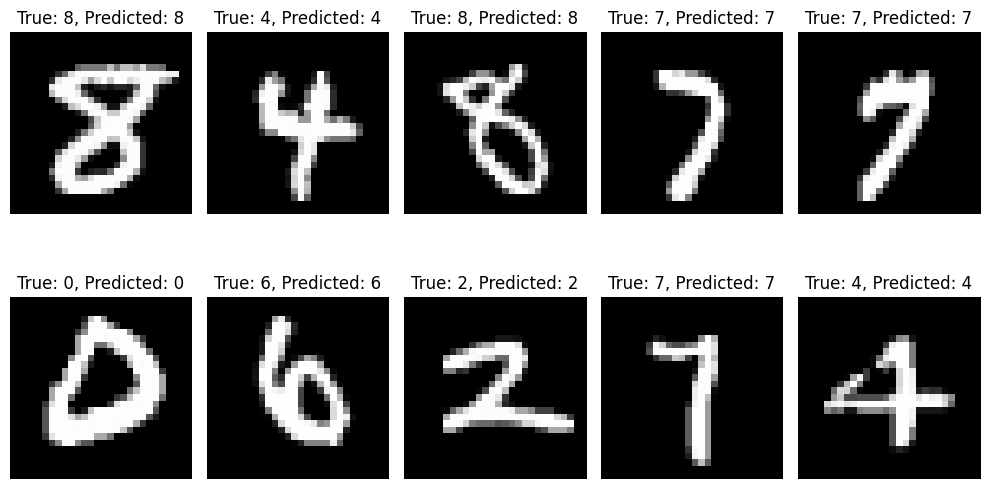

In [ ]:
plt.figure(figsize=(10,6))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test.iloc[i].values.reshape(28,28),cmap='gray')
    plt.title(f"True: {y_test.iloc[i]}, Predicted: {y_pred_mlp[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()